# [16.10] Datamodels

## Introduction

Can you predict what a model will say **before retraining it on a different training set**?

Imagine choosing half the training images at random, training a classifier from
scratch, and asking it about the same handwritten digit. Repeat with another
half. The answers change. Your job is to learn that change from a simple input:
one bit for each image saying whether it was included in training.

You will build a model of model training, inspect its coefficients as images,
and test its predictions by actually removing those images and retraining. The
most interesting result is where a convincing prediction stops working.

## Learning Objectives

- Construct the subset/output dataset used to fit a datamodel.
- Implement Lasso with a checked optimum and choose regularization on validation subsets.
- Distinguish a held-out image from a held-out training subset.
- Use datamodel weights to propose a deletion and compare it with actual retraining.
- Explain why subset size and coefficient identifiability matter for counterfactuals.

You should be comfortable with the training loops in original ARENA
[0.3 Optimization](../../../chapter0_fundamentals/exercises/part3_optimization/0.3_Optimization_exercises.ipynb).
[16.9 Influence Functions and TracIn](../part9_influence_and_tracin/README.md)
provides a useful comparison: it differentiates an optimum or follows one
training path; here we learn from many complete training runs.

Allow several hours to work through the derivations and experiments. The full
reference study runs on CPU, including every retraining. The initial data
download needs an internet connection; subsequent runs use checked source bytes.


In [1]:
from pathlib import Path
from types import SimpleNamespace
import hashlib
import json
import math
import os
import sys
import tempfile

import numpy as np
import torch
from torch import Tensor
import matplotlib.pyplot as plt
from IPython import get_ipython

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "chapter16_shapley_attribution_baselines").exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from chapter16_shapley_attribution_baselines.exercises.part10_datamodels import (
    datamodel_methods_tests as tests,
)
from chapter16_shapley_attribution_baselines.exercises.part10_datamodels.datamodel_data import (
    load_data,
    data_manifest,
)

torch.set_num_threads(4)
DTYPE = torch.float64
PART = ROOT / "chapter16_shapley_attribution_baselines/exercises/part10_datamodels"
OUTPUT = Path(os.environ.get("ARENA_DATAMODELS_OUTPUT_DIRECTORY", "/tmp/arena16_10_datamodels"))
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


def show_figure(figure, name):
    figure.tight_layout()
    figure.savefig(OUTPUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


data = load_data()
assert data_manifest(data) == json.loads((PART / "data_manifest.json").read_text())
train, query = data["train"], data["query"]


## A prediction depends on which images taught the classifier

These are actual UCI digits, with the source labels shown. We use 128 training
images of threes and eights, and 64 query images from the source's separate test
writer group. Selection uses a fixed hash of the source row; nothing is selected
for making the classifier or attribution method look good. Pixel counts are
divided by sixteen and no labels are changed.

Data: [Alpaydin and Kaynak (1998), Optical Recognition of Handwritten Digits](https://doi.org/10.24432/C50P49),
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Individual writer IDs
are unavailable. There are no exact duplicate pixel images between our two splits.

The query's label is needed to measure its correct-class margin. It is never
included in classifier training, but its margin **will** be used to fit the
datamodel. Keep those two learning problems separate.


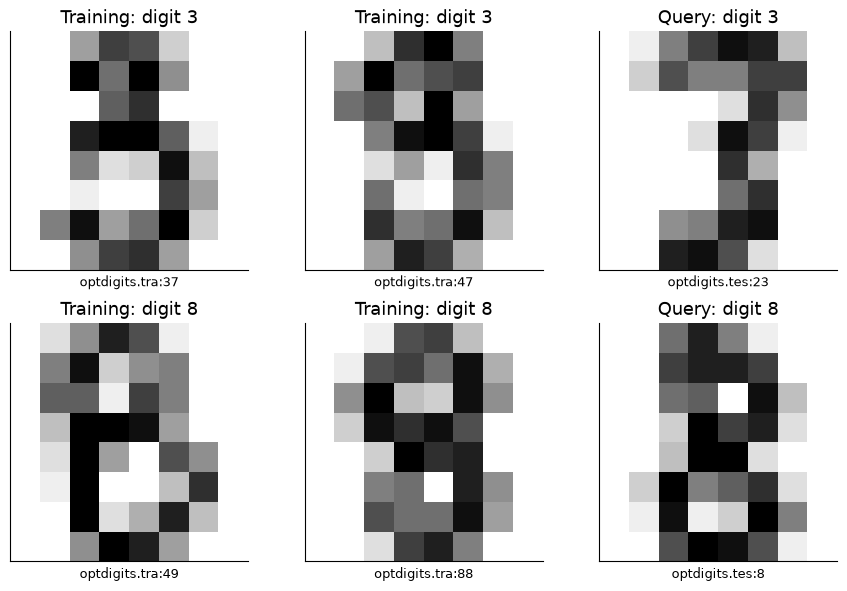

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for row, label in enumerate((0, 1)):
    ids = torch.nonzero(train["y"] == label).flatten()[:2]
    q = torch.nonzero(query["y"] == label).flatten()[0]
    for ax, split, i, role in zip(
        axes[row], [train, train, query], [*ids, q], ["Training", "Training", "Query"]
    ):
        ax.imshow(split["images"][i], cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(f"{role}: digit {split['digit'][i].item()}")
        ax.set_xlabel(split["ids"][i], fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
show_figure(fig, "datamodel_images")


## 1️⃣ Turn training into a supervised learning problem

Write the training pool as $S=\{z_1,\ldots,z_n\}$. For a subset $S'$, let
$m\in\{0,1\}^n$ be its membership mask. The learning algorithm $A$ trains a
classifier on $S'$; for a fixed target $x$, its output is $f_A(x;S')$.

Our regression examples are now pairs $(m,f_A(x;S'))$. Each **row** is one
independently trained classifier. Each **column** of $m$ corresponds to one
original training image. Training one classifier supplies outputs for every
query, so the expensive work is shared across query-specific datamodels.

We sample uniformly from subsets of size $k=\alpha n$, as in the paper. Independent
Bernoulli inclusion would vary subset size; it is a different sampling distribution.


### Exercise - sample fixed-size training subsets

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 10–15 minutes on this exercise.
> ```

Return a boolean tensor of shape `[models, training_images]`. Every row must contain exactly `size` true entries. Use a local CPU generator so this function does not change the global random state.


In [ ]:
def sample_subsets(n: int, size: int, count: int, seed: int) -> Tensor:
    """Uniform fixed-size membership masks, one independent permutation per row."""
    raise NotImplementedError()


tests.test_sample_subsets(sample_subsets)


<details>
<summary>Help - where should I start?</summary>

The first `size` positions of a uniformly random permutation form a uniform subset. Draw a new permutation for every model. Do not use a sliding window through a single permutation.

</details>

<details>
<summary>Expected output</summary>

The test checks all twenty possible size-three subsets of six items, their approximate frequencies, and exact reproducibility for a fixed seed.

</details>

<details><summary>Solution</summary>

```python
def sample_subsets(n: int, size: int, count: int, seed: int) -> Tensor:
    """Uniform fixed-size membership masks, one independent permutation per row."""
    if not 0 < size < n or count < 1:
        raise ValueError("Use a nonempty proper subset and a positive sample count.")
    generator = torch.Generator(device="cpu").manual_seed(seed)
    masks = torch.zeros(count, n, dtype=torch.bool)
    for row in range(count):
        included = torch.randperm(n, generator=generator)[:size]
        masks[row, included] = True
    return masks
```

</details>


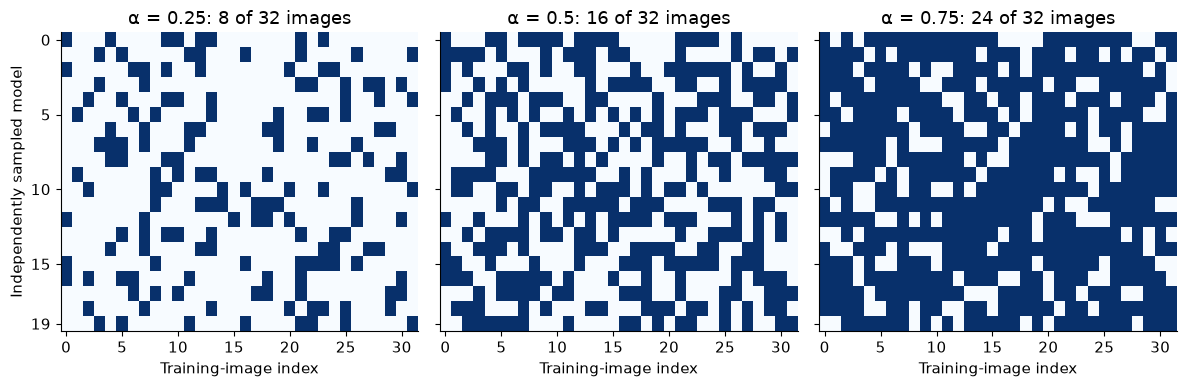

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, fraction in zip(axes, (0.25, 0.5, 0.75)):
    masks = sample_subsets(32, int(32 * fraction), 20, 1610)
    ax.imshow(masks, cmap="Blues", vmin=0, vmax=1, aspect="auto", interpolation="nearest")
    ax.set_title(f"α = {fraction}: {int(32 * fraction)} of 32 images")
    ax.set_xlabel("Training-image index")
axes[0].set_ylabel("Independently sampled model")
axes[0].set_yticks([0, 5, 10, 15, 19])
show_figure(fig, "datamodel_membership")


### Which output should the datamodel predict?

Correct/incorrect is a useful decision but discards how close we are to its
boundary. The paper uses the **correct-class margin**:

$$f_A(x;S') = h_y(x)-\max_{c\ne y}h_c(x),$$

where $h_c$ is the classifier's logit for class $c$. Positive means the true
class is strictly ahead, zero is a tie, and negative means another class wins.
Adding the same constant to every logit changes neither the margin nor the
prediction. A probability difference is not the same quantity.


### Exercise - compute the correct-class margin

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 10–15 minutes on this exercise.
> ```

Support logits shaped `[..., queries, classes]` and one integer label per query. Return `[..., queries]`, preserving every model/batch axis. Do not modify the input tensor.


In [ ]:
def correct_class_margins(logits: Tensor, labels: Tensor) -> Tensor:
    """True-class logit minus the largest other logit; preserve leading axes."""
    raise NotImplementedError()


tests.test_correct_class_margins(correct_class_margins)


<details>
<summary>Help - where should I start?</summary>

Gather the true-class logit, then exclude that class before finding the maximum competitor. Setting it to zero is wrong when all logits are negative; use negative infinity in a separate tensor.

</details>

<details>
<summary>Expected output</summary>

The fixture returns `[[4, 1], [0, -1]]`. It includes a tie, negative logits and a common logit shift.

</details>

<details><summary>Solution</summary>

```python
def correct_class_margins(logits: Tensor, labels: Tensor) -> Tensor:
    """True-class logit minus the largest other logit; preserve leading axes."""
    if logits.ndim < 2 or logits.shape[-1] < 2 or labels.shape != (logits.shape[-2],):
        raise ValueError("Expected logits [..., queries, classes] and labels [queries].")
    if labels.dtype != torch.int64 or (labels < 0).any() or (labels >= logits.shape[-1]).any():
        raise ValueError("Labels must index valid classes.")
    index = labels.expand(*logits.shape[:-1]).unsqueeze(-1)
    correct = logits.gather(-1, index).squeeze(-1)
    incorrect = logits.scatter(-1, index, -torch.inf).amax(-1)
    return correct - incorrect
```

</details>


## 2️⃣ Fit a simple surrogate to a complicated operation

For each query fit $g(m)=b+m^Tw$, with one coefficient per training image. The
target remains the output of a fully trained classifier; we are not assuming
the classifier parameters themselves are linear in membership.

We minimize an independent Lasso objective for each query:

$$J(w,b)=\frac{1}{2M}\sum_{r=1}^M (b+m_r^Tw-y_r)^2+\lambda\|w\|_1.$$

The bias is unpenalized. Center $X$ and $Y$ using **training-row means** to remove
it from the optimization, then recover $b=\bar y-\bar m^Tw$. Do not center a
validation or test set using its own mean. Our squared-error factor is half
the one in the paper's equation 8, so equivalent regularization uses half its
$\lambda$.

The L1 term can set coefficients exactly to zero. This is a modeling preference,
not a guarantee that the data will support a sparse explanation.

**Common bug:** centering validation masks or responses with their own means
changes the predictor at evaluation time. Save the training means and recover
one intercept from them; then apply that same fitted function to every split.


### Exercise - implement soft thresholding

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 10–15 minutes on this exercise.
> ```

Implement the proximal map of the L1 penalty, allowing a scalar or broadcastable nonnegative threshold. Try deriving it by considering positive, zero and negative solutions separately.


In [ ]:
def soft_threshold(values: Tensor, threshold: Tensor | float) -> Tensor:
    """Proximal map for a nonnegative elementwise L1 penalty."""
    raise NotImplementedError()


tests.test_soft_threshold(soft_threshold)


<details>
<summary>Help - where should I start?</summary>

The scalar minimizer of $(u-v)^2/2+\tau|u|$ is $\operatorname{sign}(v)\max(|v|-\tau,0)$. Thresholding the magnitude and restoring the sign avoids separate update branches.

</details>

<details>
<summary>Expected output</summary>

At threshold one, `[-3, -1, 0, 1, 3]` becomes `[-2, 0, 0, 0, 2]`. An independent grid search checks the scalar minimizer.

</details>

<details><summary>Solution</summary>

```python
def soft_threshold(values: Tensor, threshold: Tensor | float) -> Tensor:
    """Proximal map for a nonnegative elementwise L1 penalty."""
    threshold = torch.as_tensor(threshold, dtype=values.dtype, device=values.device)
    if not torch.isfinite(threshold).all() or (threshold < 0).any():
        raise ValueError("Thresholds must be finite and nonnegative.")
    return values.sign() * (values.abs() - threshold).clamp_min(0)
```

</details>


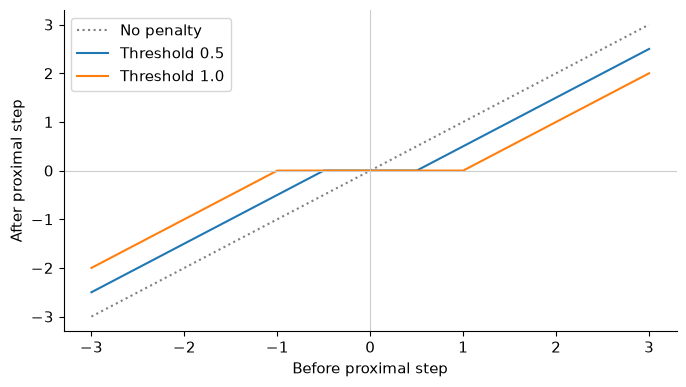

In [7]:
values = torch.linspace(-3, 3, 301, dtype=DTYPE)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(values, values, ":", color="0.5", label="No penalty")
for threshold in (0.5, 1.0):
    ax.plot(values, soft_threshold(values, threshold), label=f"Threshold {threshold}")
ax.set(xlabel="Before proximal step", ylabel="After proximal step")
ax.axhline(0, color="0.8", linewidth=0.8)
ax.axvline(0, color="0.8", linewidth=0.8)
ax.legend()
show_figure(fig, "datamodel_soft_threshold")


### How do we know the solver has finished?

With centered inputs, define $G=X_c^TX_c/M$, $C=X_c^TY_c/M$ and
$g=Gw-C$. For an optimum, every nonzero coordinate must satisfy
$g_j=-\lambda\operatorname{sign}(w_j)$, while each zero coordinate must satisfy
$|g_j|\leq\lambda$. These are the KKT conditions. Convexity makes them
sufficient for a global optimum, although the coefficients need not be unique.

We will report the largest violation. A small change between two iterates alone
does not establish these conditions: an excessively small step can barely move
an incorrect answer.


### Exercise - measure the objective and check stationarity

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 15–20 minutes on this exercise.
> ```

Return one objective and one maximum KKT violation per target. `weights` has shape `[training_images, targets]`; each target has its own penalty. For the KKT function, `gram` and `cross` already use centered training rows.


In [ ]:
def lasso_objective(x: Tensor, y: Tensor, weights: Tensor, bias: Tensor, penalty: Tensor) -> Tensor:
    """One objective per target: mean squared error / 2 plus lambda * L1."""
    raise NotImplementedError()


def lasso_kkt(gram: Tensor, cross: Tensor, weights: Tensor, penalty: Tensor) -> Tensor:
    """Maximum stationarity violation per target for centered Lasso."""
    raise NotImplementedError()


tests.test_lasso_objective(lasso_objective)
tests.test_lasso_kkt(lasso_kkt)


<details>
<summary>Help - where should I start?</summary>

For a nonzero coefficient use `abs(gradient + penalty * sign(weight))`. For a zero coefficient only the excess of `abs(gradient)` over the penalty violates stationarity. The intercept contributes squared error but never an L1 penalty.

</details>

<details>
<summary>Expected output</summary>

The objective fixture gives `[0.2, 3.15]`. The exact orthogonal-design optimum has zero KKT violation; deliberate errors produce `[1.3, 0.5]`.

</details>

<details><summary>Solution</summary>

```python
def lasso_objective(x: Tensor, y: Tensor, weights: Tensor, bias: Tensor, penalty: Tensor) -> Tensor:
    """One objective per target: mean squared error / 2 plus lambda * L1."""
    residual = x @ weights + bias - y
    return residual.square().mean(0) / 2 + penalty * weights.abs().sum(0)


def lasso_kkt(gram: Tensor, cross: Tensor, weights: Tensor, penalty: Tensor) -> Tensor:
    """Maximum stationarity violation per target for centered Lasso."""
    gradient = gram @ weights - cross
    active = (gradient + penalty * weights.sign()).abs()
    inactive = (gradient.abs() - penalty).clamp_min(0)
    return torch.where(weights != 0, active, inactive).amax(0)
```

</details>


## 3️⃣ Solve all target regressions together

A proximal-gradient step is

$$w^+=\operatorname{soft\_threshold}\left(w-\frac{Gw-C}{L},\frac{\lambda}{L}\right),$$

where $L$ is the largest eigenvalue of $G$. The same $G$ is shared by every
target, so one matrix multiplication advances all regressions. This batching
does not share their coefficients or penalties.

We use accelerated steps: extrapolate from the last two iterates with
$t^+=(1+\sqrt{1+4t^2})/2$ and coefficient $(t-1)/t^+$. If
$(z-w^+)^T(w^+-w)>0$, restart that target's acceleration. Here $z$ is the
extrapolated point. The restart is an optimization choice; the checked KKT
condition still determines whether to accept the result.

The exercise is deliberately substantial. Start with ordinary proximal gradient,
check the orthogonal fixture, then add acceleration. A zero Gram matrix needs
only the mean-response intercept.


### Exercise - fit Lasso with a checked optimum

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 30–45 minutes on this exercise.
> ```

Fit centered multi-target Lasso, recover the intercept, and return weights, bias, KKT residuals, step count and a two-column history of checked steps and the largest residual. Use `soft_threshold` and `lasso_kkt`. Stop only when all residuals satisfy `tolerance`; raise an error if the step limit is reached.


In [ ]:
def fit_lasso(
    x: Tensor,
    y: Tensor,
    penalty: Tensor,
    initial: Tensor | None = None,
    tolerance: float = 1e-8,
    max_steps: int = 20000,
) -> dict[str, Tensor | int]:
    """Accelerated proximal gradient with target-wise adaptive restart."""
    raise NotImplementedError()


tests.test_fit_lasso(fit_lasso)


<details>
<summary>Help - where should I start?</summary>

Center once, form `gram` and `cross`, and use `torch.linalg.eigvalsh(gram)[-1]` for the step scale. Maintain one acceleration time per target. Check KKT at step one, every ten steps and the final allowed step. A warm start is allowed for the regression coefficients; classifier retraining later always starts from zero.

</details>

<details>
<summary>Expected output</summary>

The test compares predictions and objective values with scikit-learn coordinate descent, including a fixed-cardinality design with non-unique coefficient offsets. Passing does not depend on selecting exactly the same representative coefficients.

</details>

<details><summary>Solution</summary>

```python
def fit_lasso(
    x: Tensor,
    y: Tensor,
    penalty: Tensor,
    initial: Tensor | None = None,
    tolerance: float = 1e-8,
    max_steps: int = 20000,
) -> dict[str, Tensor | int]:
    """Accelerated proximal gradient with target-wise adaptive restart.

    Center using training means only. The Gram matrix is shared by all targets;
    each target still has its own coefficients, penalty and acceleration state.
    A checked KKT residual, not an iteration count, certifies convergence.
    """
    if x.ndim != 2 or y.ndim != 2 or len(x) != len(y) or len(x) < 1:
        raise ValueError("Expected x [models, examples] and y [models, targets].")
    if penalty.shape != (y.shape[1],) or (penalty < 0).any() or not torch.isfinite(penalty).all():
        raise ValueError("Provide one finite nonnegative penalty per target.")
    if not torch.isfinite(x).all() or not torch.isfinite(y).all():
        raise ValueError("Regression inputs must be finite.")
    if not math.isfinite(tolerance) or tolerance <= 0 or max_steps < 1:
        raise ValueError("Use a positive finite tolerance and positive step limit.")
    x_mean, y_mean = x.mean(0), y.mean(0)
    xc, yc = x - x_mean, y - y_mean
    gram, cross = xc.T @ xc / len(x), xc.T @ yc / len(x)
    lipschitz = torch.linalg.eigvalsh(gram)[-1]
    shape = (x.shape[1], y.shape[1])
    weights = x.new_zeros(shape) if initial is None else initial.clone()
    if weights.shape != shape or not torch.isfinite(weights).all():
        raise ValueError("Initial coefficients have the wrong shape or nonfinite entries.")
    if lipschitz <= torch.finfo(x.dtype).eps:
        # Constant columns convey no information once the intercept is fitted.
        weights.zero_()
        residual = lasso_kkt(gram, cross, weights, penalty)
        return dict(
            weights=weights,
            bias=y_mean,
            kkt=residual,
            steps=0,
            history=torch.cat([x.new_zeros(1), residual.max().reshape(1)])[None],
        )
    extrapolated = weights.clone()
    momentum_time = x.new_ones(y.shape[1])
    history = []
    for step in range(1, max_steps + 1):
        gradient = gram @ extrapolated - cross
        updated = soft_threshold(extrapolated - gradient / lipschitz, penalty / lipschitz)
        next_time = (1 + torch.sqrt(1 + 4 * momentum_time.square())) / 2
        restart = ((extrapolated - updated) * (updated - weights)).sum(0) > 0
        acceleration = torch.where(restart, 0, (momentum_time - 1) / next_time)
        extrapolated = updated + acceleration * (updated - weights)
        momentum_time = torch.where(restart, 1, next_time)
        weights = updated
        if step == 1 or step % 10 == 0 or step == max_steps:
            residual = lasso_kkt(gram, cross, weights, penalty)
            history.append(torch.stack([x.new_tensor(step), residual.max()]))
            if (residual <= tolerance).all():
                return dict(
                    weights=weights,
                    bias=y_mean - x_mean @ weights,
                    kkt=residual,
                    steps=step,
                    history=torch.stack(history),
                )
    raise RuntimeError(f"Lasso did not converge: maximum KKT residual {residual.max().item():.3g}.")
```

</details>


## 4️⃣ Choose regularization without reading test responses

For centered training rows, $\lambda_{\max}=\max_j|C_j|$ makes the zero weight
vector optimal. Fit a descending path from that value to $10^{-4}$ of it. Each
query gets its own scale and its own validation choice. On an exact tie, keep
the earlier, more regularized path point.

The regression train/validation/test split is a split over **trained models**.
All three can evaluate the same fixed query image. Reusing a model in two splits
would leak its response, even if the response was saved under a different filename.

We retain the whole path. A selected endpoint is evidence that the best penalty
may lie beyond the tested range; it is not proof that we found the globally
best hyperparameter.


### Exercise - fit and validate a regularization path

> ```yaml
> Difficulty: 🔴🔴🔴🔴⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 20–30 minutes on this exercise.
> ```

Fit every penalty on the training subset/output pairs, warm-starting from the previous path point. Compute validation MSE per query and select its minimum. Return the complete path as well as the selected weight and bias for each query. The function deliberately has no test-response argument.


In [ ]:
def fit_datamodel_path(
    x_train: Tensor,
    y_train: Tensor,
    x_val: Tensor,
    y_val: Tensor,
    fractions: Tensor,
) -> dict[str, Tensor]:
    """Fit every path point on train rows, then select per target on validation."""
    raise NotImplementedError()


tests.test_fit_datamodel_path(fit_datamodel_path)


<details>
<summary>Help - where should I start?</summary>

Use training means for `lambda_max`. Stack weights as `[path, images, targets]` and validation losses as `[path, targets]`. Advanced indexing can transpose selected axes unexpectedly; explicitly check that selected weights are `[images, targets]`.

</details>

<details>
<summary>Expected output</summary>

The synthetic test chooses path indices `[2, 0]`: a predictive target prefers less shrinkage, while a constant target ties and chooses the first index. Changing validation labels must leave every fitted path coefficient unchanged.

</details>

<details><summary>Solution</summary>

```python
def fit_datamodel_path(
    x_train: Tensor,
    y_train: Tensor,
    x_val: Tensor,
    y_val: Tensor,
    fractions: Tensor,
) -> dict[str, Tensor]:
    """Fit every path point on train rows, then select per target on validation."""
    if fractions.ndim != 1 or len(fractions) < 1 or not torch.isfinite(fractions).all():
        raise ValueError("Use a nonempty finite path of penalty fractions.")
    if (fractions <= 0).any() or (fractions > 1).any() or (fractions[1:] > fractions[:-1]).any():
        raise ValueError("Penalty fractions must descend within (0, 1].")
    if x_val.shape[1:] != x_train.shape[1:] or y_val.shape != (len(x_val), y_train.shape[1]):
        raise ValueError("Validation masks and targets must align with the training axes.")
    xc, yc = x_train - x_train.mean(0), y_train - y_train.mean(0)
    lambda_max = (xc.T @ yc / len(x_train)).abs().amax(0)
    weights, biases, residuals, steps, validation, penalties = [], [], [], [], [], []
    initial = None
    for fraction in fractions:
        penalty = fraction * lambda_max
        fit = fit_lasso(x_train, y_train, penalty, initial=initial)
        initial = fit["weights"]
        weights.append(fit["weights"])
        biases.append(fit["bias"])
        residuals.append(fit["kkt"])
        steps.append(fit["steps"])
        penalties.append(penalty)
        prediction = x_val @ fit["weights"] + fit["bias"]
        validation.append((prediction - y_val).square().mean(0))
    weights, biases = torch.stack(weights), torch.stack(biases)
    validation = torch.stack(validation)
    selected = validation.argmin(0)  # First path index wins exact ties.
    targets = torch.arange(y_train.shape[1], device=x_train.device)
    return dict(
        weights=weights,
        bias=biases,
        penalty=torch.stack(penalties),
        kkt=torch.stack(residuals),
        steps=torch.tensor(steps),
        validation_mse=validation,
        selected=selected,
        selected_weights=weights[selected, :, targets].T,
        selected_bias=biases[selected, targets],
    )
```

</details>


### Try It Yourself — when is a linear datamodel insufficient?

This small, exact fixture separates solver error from model misspecification.
Its output is a sparse linear membership function plus an optional interaction.
The interaction makes one training example's effect depend on another's presence.

Change `INTERACTION` from zero to one or two, or change `SUBSET_SIZE`. The seed
and row splits stay fixed. Compare held-out predictions with the identity line
and the mean-response baseline. Stronger interactions cannot be repaired merely
by driving the Lasso optimization residual closer to zero.


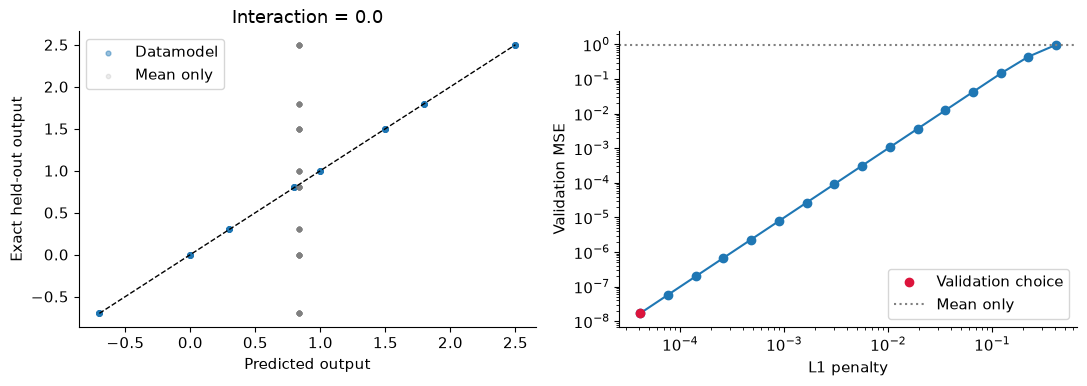

In [11]:
INTERACTION = 0.0
SUBSET_SIZE = 12

fixture_masks = [
    sample_subsets(24, SUBSET_SIZE, count, seed).double()
    for count, seed in ((384, 31), (128, 32), (256, 33))
]
fixture_weights = torch.zeros(24, 1, dtype=DTYPE)
fixture_weights[[0, 4, 11], 0] = torch.tensor([1.5, -1.0, 0.7], dtype=DTYPE)


def fixture_response(x):
    interaction = (x[:, 1] - x[:, 2]) * (x[:, 7] - x[:, 8])
    return 0.3 + x @ fixture_weights + INTERACTION * interaction[:, None]


fixture_y = [fixture_response(x) for x in fixture_masks]
fixture_path = fit_datamodel_path(
    *[fixture_masks[0], fixture_y[0], fixture_masks[1], fixture_y[1]],
    torch.logspace(0, -4, 16, dtype=DTYPE),
)
fixture_pred = fixture_masks[2] @ fixture_path["selected_weights"] + fixture_path["selected_bias"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(fixture_pred[:, 0], fixture_y[2][:, 0], s=12, alpha=0.45, label="Datamodel")
axes[0].scatter(
    torch.full_like(fixture_y[2][:, 0], fixture_y[0].mean()),
    fixture_y[2][:, 0],
    s=10,
    alpha=0.15,
    color="0.5",
    label="Mean only",
)
bounds = [float(fixture_y[2].min()), float(fixture_y[2].max())]
axes[0].plot(bounds, bounds, "k--", linewidth=1)
axes[0].set(
    xlabel="Predicted output", ylabel="Exact held-out output", title=f"Interaction = {INTERACTION}"
)
axes[0].legend()
axes[1].plot(fixture_path["penalty"][:, 0], fixture_path["validation_mse"][:, 0], "o-")
chosen = fixture_path["selected"][0]
axes[1].scatter(
    fixture_path["penalty"][chosen, 0],
    fixture_path["validation_mse"][chosen, 0],
    color="crimson",
    zorder=3,
    label="Validation choice",
)
axes[1].axhline(
    float((fixture_y[1] - fixture_y[0].mean()).square().mean()),
    color="0.5",
    linestyle=":",
    label="Mean only",
)
axes[1].set(xscale="log", yscale="log", xlabel="L1 penalty", ylabel="Validation MSE")
axes[1].legend()
show_figure(fig, "datamodel_fixture_play")


## 5️⃣ A coefficient offset you cannot identify

Every fixed-size mask obeys $m^T\mathbf{1}=k$. Consequently,

$$m^T(w+c\mathbf{1})+(b-kc)=m^Tw+b.$$

The same-size data cannot distinguish these coefficient/bias pairs. An L1
penalty prefers representatives with a small absolute coefficient sum, but that
choice does not identify an underlying causal offset. For a different size
$k'$, the predictions differ by $(k'-k)c$.

Try deriving the difference for removing $r$ images from the full pool: the
predicted change shifts by $-rc$. Rankings are unchanged. A method can therefore
agree about **which** images to remove while disagreeing about **how much** the
margin should change.


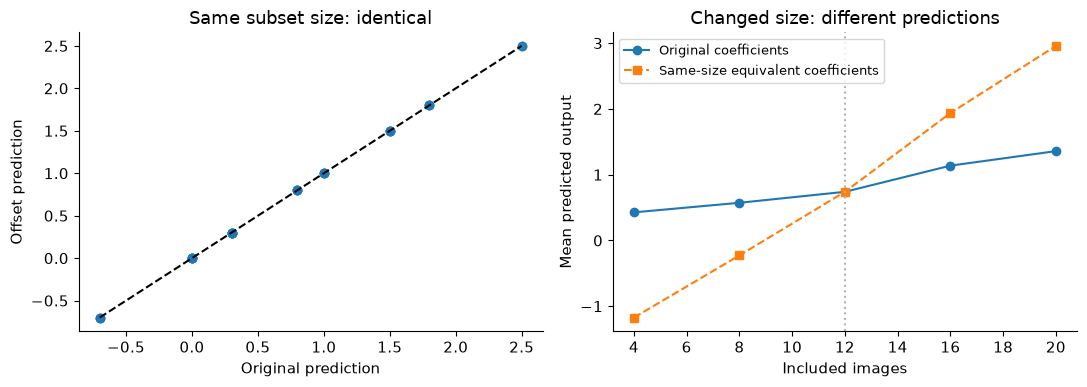

In [12]:
gauge_masks = sample_subsets(24, 12, 48, 615).double()
gauge_w = fixture_path["selected_weights"][:, 0]
gauge_b = fixture_path["selected_bias"][0]
offset = 0.2
original = gauge_masks @ gauge_w + gauge_b
shifted = gauge_masks @ (gauge_w + offset) + gauge_b - 12 * offset
torch.testing.assert_close(original, shifted)
sizes = [4, 8, 12, 16, 20]
means, shifted_means = [], []
for size in sizes:
    masks = sample_subsets(24, size, 48, 615).double()
    means.append(float((masks @ gauge_w + gauge_b).mean()))
    shifted_means.append(float((masks @ (gauge_w + offset) + gauge_b - 12 * offset).mean()))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(original, shifted, alpha=0.6)
axes[0].plot(
    [float(original.min()), float(original.max())],
    [float(original.min()), float(original.max())],
    "k--",
)
axes[0].set(
    xlabel="Original prediction", ylabel="Offset prediction", title="Same subset size: identical"
)
axes[1].plot(sizes, means, "o-", label="Original coefficients")
axes[1].plot(sizes, shifted_means, "s--", label="Same-size equivalent coefficients")
axes[1].axvline(12, color="0.7", linestyle=":")
axes[1].set(
    xlabel="Included images",
    ylabel="Mean predicted output",
    title="Changed size: different predictions",
)
axes[1].legend(fontsize=9)
show_figure(fig, "datamodel_gauge")


### Exercise - compare datamodel directions

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 10–15 minutes on this exercise.
> ```

Treat each target’s weights as an embedding and return a `[targets, targets]` cosine-similarity matrix. Remove each target’s mean coefficient first so the result is invariant to arbitrary common offsets. Give an all-constant vector zero similarity rather than dividing by zero.


In [ ]:
def centered_weight_similarity(weights: Tensor) -> Tensor:
    """Cosine similarity of target datamodels, invariant to target-wise offsets."""
    raise NotImplementedError()


tests.test_centered_weight_similarity(centered_weight_similarity)


<details>
<summary>Help - where should I start?</summary>

The training-image axis is the first axis. Center along it, normalize each column, and multiply normalized columns by one another. Centered cosine is our explicitly chosen comparison, not a claim that the paper used this exact normalization.

</details>

<details>
<summary>Expected output</summary>

The fixture includes identical, opposite and constant directions. Adding a separate offset to every target leaves the matrix unchanged.

</details>

<details><summary>Solution</summary>

```python
def centered_weight_similarity(weights: Tensor) -> Tensor:
    """Cosine similarity of target datamodels, invariant to target-wise offsets."""
    centered = weights - weights.mean(0, keepdim=True)
    norms = centered.norm(dim=0)
    normalized = centered / norms.clamp_min(torch.finfo(weights.dtype).eps)
    return normalized.T @ normalized
```

</details>


## 6️⃣ Propose a deletion, then test it

For a query with weight vector $w$, removing indices $R$ changes the datamodel
prediction by $-\sum_{i\in R}w_i$. To reduce the margin, remove the largest
weights. This is a proposal, not an observed effect. We must train on $S\setminus R$
to find out what happens.

Removing many examples of one class changes the class balance. Our random
controls match the selected deletion's number of threes and eights exactly.
They answer whether these particular images matter beyond that class composition.
They may overlap the selected set by chance; do not exclude overlaps artificially.


### Exercise - select supportive images and match random controls

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
>
> You should spend up to 15–20 minutes on this exercise.
> ```

Select the largest `budget` scores with stable source-order ties. Then sample random index sets without replacement, matching the selected set’s count in every observed class. Return sorted indices for easy comparison; do not use the query outcome to choose controls.


In [ ]:
def select_supportive(scores: Tensor, budget: int) -> Tensor:
    """Indices with largest scores, breaking ties by the original source order."""
    raise NotImplementedError()


def matched_random_removals(labels: Tensor, selected: Tensor, count: int, seed: int) -> Tensor:
    """Random index sets matching the selected set's count in every class."""
    raise NotImplementedError()


tests.test_select_supportive(select_supportive)
tests.test_matched_random_removals(matched_random_removals)


<details>
<summary>Help - where should I start?</summary>

Sort the scores descending with `stable=True`. For each random replicate, independently permute the available indices within each class and take the required count. Matching labels means matching the labels actually used for training.

</details>

<details>
<summary>Expected output</summary>

The selection fixture keeps indices `[1, 4]`. Every random control in the three-class fixture removes exactly `[1, 2, 1]` examples from the three classes.

</details>

<details><summary>Solution</summary>

```python
def select_supportive(scores: Tensor, budget: int) -> Tensor:
    """Indices with largest scores, breaking ties by the original source order."""
    if scores.ndim != 1 or not torch.isfinite(scores).all() or not 0 <= budget < len(scores):
        raise ValueError("Provide finite scores and a budget leaving at least one example.")
    return torch.argsort(scores, descending=True, stable=True)[:budget].sort().values


def matched_random_removals(labels: Tensor, selected: Tensor, count: int, seed: int) -> Tensor:
    """Random index sets matching the selected set's count in every class."""
    if labels.ndim != 1 or labels.dtype != torch.int64 or selected.dtype != torch.int64:
        raise ValueError("Labels and selected indices must be integer vectors.")
    if selected.ndim != 1 or len(selected.unique()) != len(selected) or count < 1:
        raise ValueError("Use distinct selected indices and a positive control count.")
    if (selected < 0).any() or (selected >= len(labels)).any():
        raise ValueError("Selected indices are outside the training pool.")
    generator = torch.Generator(device="cpu").manual_seed(seed)
    sets = []
    for _ in range(count):
        pieces = []
        for label in labels.unique(sorted=True):
            candidates = torch.nonzero(labels == label).flatten()
            number = int((labels[selected] == label).sum())
            permutation = torch.randperm(len(candidates), generator=generator)
            pieces.append(candidates[permutation[:number]])
        sets.append(torch.cat(pieces).sort().values)
    return torch.stack(sets)
```

</details>


## 7️⃣ Train the real subset models

The classifier is the regularized logistic model from 16.9: mean cross-entropy
plus $0.02\|\theta\|^2/2$, including the bias. Every subset fit starts at zero
and converges to a gradient infinity norm below $10^{-10}$. Batching accelerates
independent fits; it does not continue one model's training inside another.

This choice isolates variation due to training subsets. There is no random
initialization or stochastic optimization noise floor to estimate here. The
paper's deep-network experiments have both sources of variation; their procedure
averages multiple trainings when estimating expected outputs.

For each $\alpha\in\{0.25,0.5,0.75\}$ we fit 1,024 training-subset models and
128 validation-subset models. Another 256 models per fraction are held out for
evaluation. Each fit supplies margins for all 64 queries. The datamodel never
receives pixels as regression inputs—only membership bits.

The following driver connects your functions. The classifier optimizer is the
only reused method, linked and taught in 16.9. All subset sampling, regression,
selection, prediction and intervention logic is visible below.


In [15]:
from chapter16_shapley_attribution_baselines.exercises.part9_influence_and_tracin.attribution_methods import (
    fit_weighted_logistic,
)

FRACTIONS = (0.25, 0.5, 0.75)
BUDGETS = (2, 8, 16, 32)


In [16]:
def make_designs(methods) -> dict:
    """Build and check the prescribed mask splits without fitting any classifier."""
    designs = {}
    for a, fraction in enumerate(FRACTIONS):
        sizes = (("train", 1024), ("validation", 128), ("test", 256))
        design = {
            name: methods.sample_subsets(128, int(fraction * 128), count, 161000 + 100 * a + split)
            for split, (name, count) in enumerate(sizes)
        }
        together = torch.cat(list(design.values()))
        if together.unique(dim=0).shape[0] != len(together):
            raise ValueError("A duplicate subset crossed or appeared within the prescribed splits.")
        designs[fraction] = design
    return designs


def refit_masks(train: dict, masks: Tensor) -> dict[str, Tensor]:
    """Batched independent classifier fits using the optimizer taught in 16.9."""
    if masks.ndim != 2 or masks.shape[1] != len(train["x"]) or masks.dtype != torch.bool:
        raise ValueError("Provide boolean training membership masks.")
    if (masks.sum(1) == 0).any():
        raise ValueError("A model cannot be trained on an empty subset.")
    weights, gradients, objectives = [], [], []
    for batch in masks.split(128):
        fit = fit_weighted_logistic(train["x"], train["y"], batch.double(), l2=0.02)
        weights.append(fit["theta"])
        gradients.append(fit["gradient_norms"][-1])
        objectives.append(fit["objective"])
    return dict(
        theta=torch.cat(weights),
        gradient_norm=torch.cat(gradients),
        objective=torch.cat(objectives),
    )


def model_margins(fit: dict, query: dict, methods) -> Tensor:
    logit = fit["theta"] @ query["x"].T
    two_class_logits = torch.stack([torch.zeros_like(logit), logit], dim=-1)
    return methods.correct_class_margins(two_class_logits, query["y"])


def least_squares_datamodel(x: Tensor, y: Tensor) -> dict[str, Tensor]:
    """Unpenalized minimum-norm baseline; center on training rows only."""
    xc, yc = x - x.mean(0), y - y.mean(0)
    weights = torch.linalg.lstsq(xc, yc, driver="gelsd").solution
    return dict(weights=weights, bias=y.mean(0) - x.mean(0) @ weights)


### What will count as a useful prediction?

We compare Lasso with an intercept-only predictor, minimum-norm least squares,
and a control that permutes the association between training masks and responses.
The permutation preserves the response values, but destroys which subset produced
each one. It receives the same validation procedure as Lasso.

At $\alpha=0.5$ we also use the first 64, 128, 256 and 512 training-subset models.
This gives a sample-complexity curve without retraining or choosing favorable
samples. Every point uses the same separate validation and test subsets.

The deletion experiment uses 24 fixed queries: the first twelve source-ordered
queries in each class. Four rankings propose deletions: one datamodel for each
fraction and signed pixel cosine similarity. Every ranking/query/budget has
sixteen class-matched random controls. We construct all 6,528 masks before
reading their outcomes.


In [17]:
def fit_response_models(x: Tensor, y: Tensor, xv: Tensor, yv: Tensor, methods) -> dict:
    """Lasso and controls see only their fit and validation subset responses."""
    penalties = torch.logspace(0, -4, 16, dtype=x.dtype)
    result = {"lasso": methods.fit_datamodel_path(x, y, xv, yv, penalties)}
    permutation = torch.randperm(len(y), generator=torch.Generator().manual_seed(161440))
    result["permuted"] = methods.fit_datamodel_path(x, y[permutation], xv, yv, penalties)
    result["permutation"] = permutation
    result["least_squares"] = least_squares_datamodel(x, y)
    result["intercept"] = y.mean(0)
    return result


def build_deletion_masks(train: dict, query: dict, responses: dict, methods) -> dict:
    """Freeze all selected and matched control sets before seeing refit outcomes."""
    query_ids = (
        torch.cat([torch.nonzero(query["y"] == label).flatten()[:12] for label in (0, 1)])
        .sort()
        .values
    )
    pixel = torch.nn.functional.normalize(train["x"][:, :64], dim=1)
    target_pixel = torch.nn.functional.normalize(query["x"][:, :64], dim=1)
    pixel_scores = (pixel @ target_pixel.T) * torch.where(
        train["y"][:, None] == query["y"][None], 1.0, -1.0
    )
    all_scores = [responses[a]["lasso"]["selected_weights"] for a in FRACTIONS] + [pixel_scores]
    masks, target, budget_values, method_values, replicate, class_counts = [], [], [], [], [], []
    for method_index, scores in enumerate(all_scores):
        for position, q in enumerate(query_ids.tolist()):
            for budget in BUDGETS:
                selected = methods.select_supportive(scores[:, q], budget)
                seed = 162000 + 10000 * method_index + 100 * position + budget
                controls = methods.matched_random_removals(train["y"], selected, 16, seed)
                for rep, removed in enumerate(torch.cat([selected[None], controls])):
                    mask = torch.ones(len(train["y"]), dtype=torch.bool)
                    mask[removed] = False
                    masks.append(mask)
                    target.append(q)
                    budget_values.append(budget)
                    method_values.append(method_index)
                    replicate.append(rep - 1)
                    class_counts.append(torch.bincount(train["y"][removed], minlength=2))
    return dict(
        masks=torch.stack(masks),
        target=torch.tensor(target),
        budget=torch.tensor(budget_values),
        method=torch.tensor(method_values),
        replicate=torch.tensor(replicate),
        removed_class_counts=torch.stack(class_counts),
        query_indices=query_ids,
        pixel_scores=pixel_scores,
    )


def prepare_study(train: dict, query: dict, designs: dict, methods, directory: Path) -> dict:
    """Fit/validate datamodels and construct deletions; never fit test subsets."""
    directory.mkdir(parents=True, exist_ok=False)
    subset_fits, outputs, responses, learning = {}, {}, {}, {}
    for fraction in FRACTIONS:
        fit = {
            name: refit_masks(train, designs[fraction][name]) for name in ("train", "validation")
        }
        margins = {name: model_margins(value, query, methods) for name, value in fit.items()}
        x, xv = [designs[fraction][name].double() for name in ("train", "validation")]
        y, yv = margins["train"], margins["validation"]
        response = fit_response_models(x, y, xv, yv, methods)
        if fraction == 0.5:
            for count in (64, 128, 256, 512):
                learning[count] = fit_response_models(x[:count], y[:count], xv, yv, methods)
        subset_fits[fraction], outputs[fraction], responses[fraction] = fit, margins, response
    deletions = build_deletion_masks(train, query, responses, methods)
    result = dict(
        phase="FIT_VALIDATION_AND_DELETION_SELECTION_COMPLETE",
        designs=designs,
        subset_fits=subset_fits,
        margins=outputs,
        responses=responses,
        learning=learning,
        deletions=deletions,
        training_ids=train["ids"],
        query_ids=query["ids"],
        test_subset_responses_seen=False,
        counterfactual_responses_seen=False,
    )
    torch.save(result, directory / "prepared.pt")
    return result


In [18]:
method_names = [
    "sample_subsets",
    "correct_class_margins",
    "fit_datamodel_path",
    "select_supportive",
    "matched_random_removals",
]
methods = SimpleNamespace(**{name: globals()[name] for name in method_names})
designs = make_designs(methods)
NATIVE = Path(tempfile.mkdtemp(prefix="native-", dir=OUTPUT)) / "study"
prepared = prepare_study(train, query, designs, methods, NATIVE)
boundary = {
    "phase": prepared["phase"],
    "prepared_sha256": hashlib.sha256((NATIVE / "prepared.pt").read_bytes()).hexdigest(),
    "test_subset_responses_seen": False,
    "counterfactual_responses_seen": False,
}
(OUTPUT / "selection_boundary.json").write_text(json.dumps(boundary, indent=2) + "\n")
print(
    "3,456 classifier fits complete. All paths and deletion masks fixed; test responses still unseen."
)


3,456 classifier fits complete. All paths and deletion masks fixed; test responses still unseen.


### Inspect the validation path before opening the test responses

The left plot shows validation error relative to the mean-only baseline. The
middle plot shows the median number of nonzero coefficients; the right plot
shows which path points were selected. Bands describe variation across the 64
queries, not confidence intervals.

On this problem the selected explanations are mostly dense: the median count
is 126, 126 and 128 of 128 coefficients at the three fractions. Many queries
select the least-regularized endpoint. Keep that result. Lasso's sparsity prior
does not make a sparse explanation appropriate for every learning algorithm.


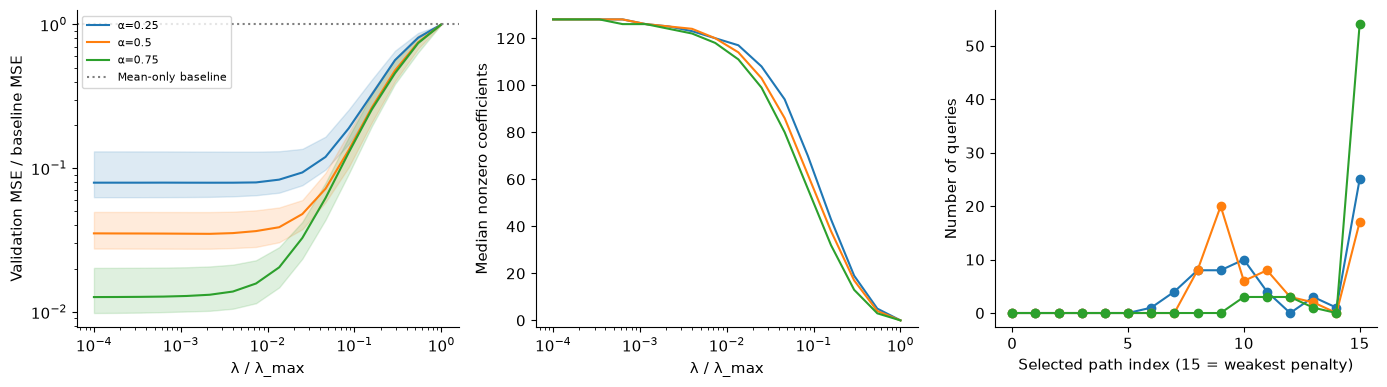

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
path_fractions = torch.logspace(0, -4, 16, dtype=DTYPE)
for fraction, color in zip(FRACTIONS, ("C0", "C1", "C2")):
    response = prepared["responses"][fraction]
    path = response["lasso"]
    yv = prepared["margins"][fraction]["validation"]
    baseline = (yv - response["intercept"]).square().mean(0)
    ratio = path["validation_mse"] / baseline
    axes[0].plot(path_fractions, ratio.median(1).values, color=color, label=f"α={fraction}")
    axes[0].fill_between(
        path_fractions,
        ratio.quantile(0.1, dim=1),
        ratio.quantile(0.9, dim=1),
        color=color,
        alpha=0.15,
    )
    axes[1].plot(
        path_fractions, (path["weights"] != 0).sum(1).double().median(1).values, color=color
    )
    axes[2].plot(range(16), torch.bincount(path["selected"], minlength=16), "o-", color=color)
axes[0].axhline(1, color="0.5", linestyle=":", label="Mean-only baseline")
axes[0].set(xscale="log", yscale="log", xlabel="λ / λ_max", ylabel="Validation MSE / baseline MSE")
axes[0].legend(fontsize=8)
axes[1].set(xscale="log", xlabel="λ / λ_max", ylabel="Median nonzero coefficients", ylim=(-3, 132))
axes[2].set(
    xlabel="Selected path index (15 = weakest penalty)",
    ylabel="Number of queries",
    xticks=[0, 5, 10, 15],
)
show_figure(fig, "datamodel_validation_path")


## 8️⃣ Open the held-out subset results

Now train the held-out models and evaluate the frozen choices. There is no
regularization selection in this function. It also performs the full-pool and
counterfactual fits; their masks have already been fixed.

The main signature result is a prediction made from membership alone, compared
with the margin obtained after actual retraining. We first subtract each query's
test mean from both axes for plotting. This visualization removes between-query
offsets; it does **not** change predictions or evaluation metrics. Without this
view, a pooled correlation could mostly reflect that some digits are always easy.


In [20]:
def response_predictions(response: dict, masks: Tensor) -> dict[str, Tensor]:
    x = masks.double()
    predictions = {}
    for name in ("lasso", "permuted"):
        model = response[name]
        predictions[name] = x @ model["selected_weights"] + model["selected_bias"]
    model = response["least_squares"]
    predictions["least_squares"] = x @ model["weights"] + model["bias"]
    predictions["intercept"] = response["intercept"].expand(len(x), -1)
    return predictions


def evaluate_study(prepared: dict, train: dict, query: dict, methods, directory: Path) -> dict:
    """Retrain held-out subsets and frozen counterfactuals, with no model selection."""
    if prepared.get("phase") != "FIT_VALIDATION_AND_DELETION_SELECTION_COMPLETE":
        raise ValueError("Complete all datamodel fitting and deletion selection before evaluation.")
    if prepared["training_ids"] != train["ids"] or prepared["query_ids"] != query["ids"]:
        raise ValueError("Data row identity/order changed between preparation and evaluation.")
    if prepared["test_subset_responses_seen"] or prepared["counterfactual_responses_seen"]:
        raise ValueError("The prepared experiment claims it already inspected evaluation outcomes.")
    tests, cross_fraction, learning_predictions = {}, {}, {}
    for fraction in FRACTIONS:
        masks = prepared["designs"][fraction]["test"]
        fit = refit_masks(train, masks)
        margin = model_margins(fit, query, methods)
        predictions = response_predictions(prepared["responses"][fraction], masks)
        tests[fraction] = dict(fit=fit, margin=margin, predictions=predictions)
        cross_fraction[fraction] = {
            source: response_predictions(prepared["responses"][source], masks)["lasso"]
            for source in FRACTIONS
        }
        if fraction == 0.5:
            for count, response in prepared["learning"].items():
                learning_predictions[count] = response_predictions(response, masks)
    base_fit = refit_masks(train, torch.ones(1, len(train["y"]), dtype=torch.bool))
    base_margin = model_margins(base_fit, query, methods)[0]
    deletion = prepared["deletions"]
    refits = refit_masks(train, deletion["masks"])
    all_margin = model_margins(refits, query, methods)
    rows = torch.arange(len(all_margin))
    query_index = deletion["target"]
    target_margin = all_margin[rows, query_index]
    prediction = []
    for fraction in FRACTIONS:
        weights = prepared["responses"][fraction]["lasso"]["selected_weights"]
        full_changes = -(~deletion["masks"]).double() @ weights
        prediction.append(full_changes[rows, query_index])
    result = dict(
        phase="FROZEN_EVALUATION_COMPLETE",
        test=tests,
        cross_fraction=cross_fraction,
        learning_predictions=learning_predictions,
        base_fit=base_fit,
        base_margin=base_margin,
        counterfactual=dict(
            fit=refits,
            all_margin=all_margin,
            target_margin=target_margin,
            actual_change=target_margin - base_margin[query_index],
            predicted_change=torch.stack(prediction, dim=1),
        ),
        selection_used_test_responses=False,
    )
    torch.save(result, directory / "evaluated.pt")
    return result


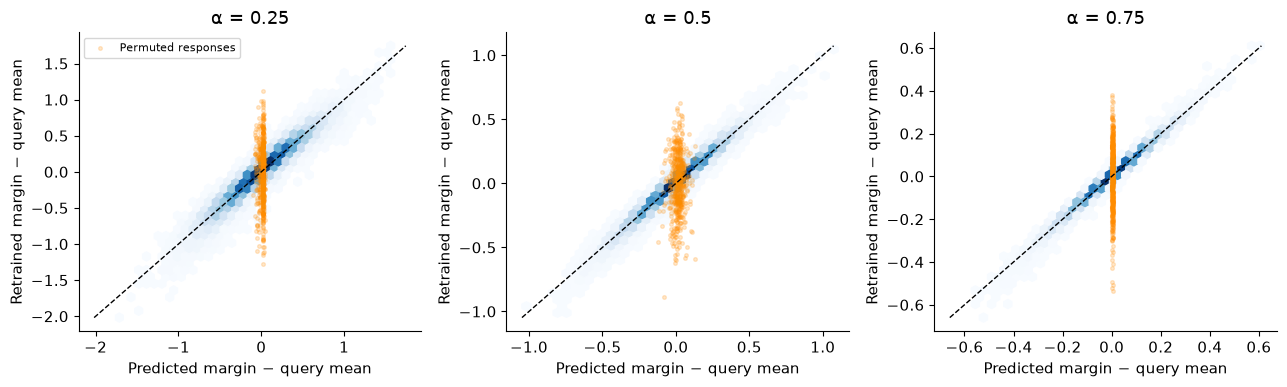

In [21]:
evaluated = evaluate_study(prepared, train, query, methods, NATIVE)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, fraction in zip(axes, FRACTIONS):
    result = evaluated["test"][fraction]
    observed = result["margin"]
    center = observed.mean(0)
    predicted = result["predictions"]["lasso"]
    xp, yp = (predicted - center).flatten().numpy(), (observed - center).flatten().numpy()
    ax.hexbin(xp, yp, gridsize=35, mincnt=1, cmap="Blues")
    control = (result["predictions"]["permuted"] - center).flatten().numpy()
    ax.scatter(
        control[::32], yp[::32], color="darkorange", alpha=0.2, s=7, label="Permuted responses"
    )
    limits = [min(xp.min(), yp.min()), max(xp.max(), yp.max())]
    ax.plot(limits, limits, "k--", linewidth=1)
    ax.set(
        xlabel="Predicted margin − query mean",
        ylabel="Retrained margin − query mean",
        title=f"α = {fraction}",
    )
axes[0].legend(fontsize=8)
show_figure(fig, "datamodel_heldout_predictions")


The blue density follows the identity line; the permuted-response control mostly
predicts each query's average. But how well does this hold for the individual
queries? The next plot gives every query its own $R^2$:

$$R_x^2=1-\frac{\sum_r(\widehat f_{rx}-f_{rx})^2}{\sum_r(f_{rx}-\overline f_x)^2}.$$

An $R^2$ near one means we predict the subset-dependent variation. Zero is the
test-mean baseline and negative values are possible. Our actual intercept-only
model uses a training mean, so it need not land exactly at zero.

The worst query still has $R^2$ about 0.86, 0.94 and 0.98 as the subset fraction
increases. Least squares is very competitive, sometimes slightly better.
We retain that baseline instead of claiming that L1 regularization caused the
strong predictions.


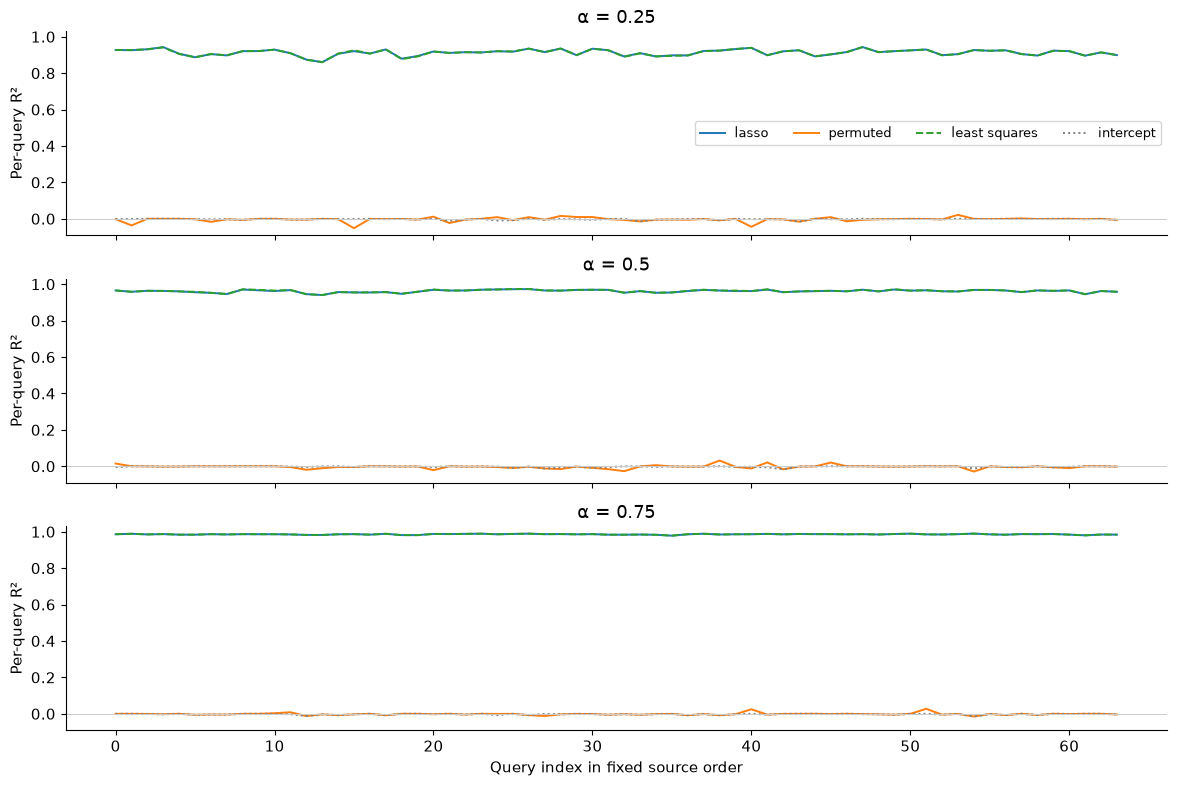

In [22]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
styles = {
    "lasso": ("C0", "-"),
    "least_squares": ("C2", "--"),
    "permuted": ("C1", "-"),
    "intercept": ("0.5", ":"),
}
for ax, fraction in zip(axes, FRACTIONS):
    result = evaluated["test"][fraction]
    observed = result["margin"]
    for name, prediction in result["predictions"].items():
        mse = (prediction - observed).square().mean(0)
        r2 = 1 - mse / observed.var(0, unbiased=False)
        color, linestyle = styles[name]
        ax.plot(r2, label=name.replace("_", " "), color=color, linestyle=linestyle, linewidth=1.4)
    ax.set(ylabel="Per-query R²", title=f"α = {fraction}", ylim=(-0.09, 1.03))
    ax.axhline(0, color="0.8", linewidth=0.7)
axes[0].legend(ncol=4, fontsize=9)
axes[-1].set_xlabel("Query index in fixed source order")
show_figure(fig, "datamodel_query_r2")


### What did the extra training runs buy?

Keep the test set fixed and vary the number of subset/response pairs used for
regression. The left plot averages squared error over the same 64 queries and
256 held-out models. The right plot shows selected Lasso density. Comparing
against unpenalized least squares is particularly useful when the number of
observed training runs is comparable to the 128 coefficients.

Least-squares error spikes near 128 training models in this run. The third
panel diagnoses sensitivity: the condition number of the nonzero singular
values rises to about 218 there, compared with about 5.4 at 256 models.
The structural zero direction from fixed cardinality is excluded. This is
consistent with amplification of residuals that a linear surrogate cannot
fit; it is not evidence that the optimizer failed to solve least squares.


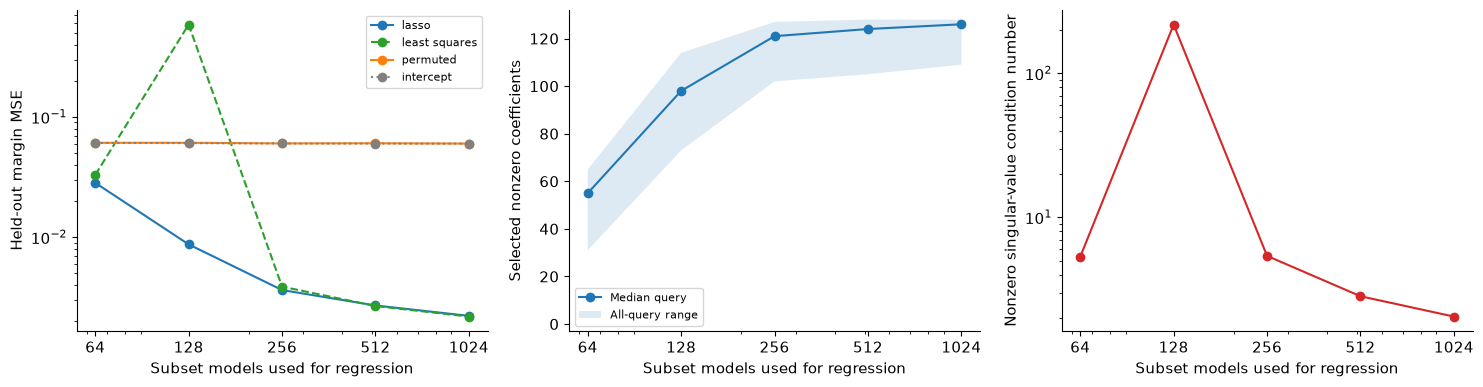

In [23]:
counts = [64, 128, 256, 512, 1024]
observed = evaluated["test"][0.5]["margin"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, (color, linestyle) in styles.items():
    errors = []
    for count in counts:
        predictions = (
            evaluated["test"][0.5]["predictions"]
            if count == 1024
            else evaluated["learning_predictions"][count]
        )
        errors.append(float((predictions[name] - observed).square().mean()))
    axes[0].plot(
        counts, errors, "o", linestyle=linestyle, color=color, label=name.replace("_", " ")
    )
densities = []
for count in counts:
    response = prepared["responses"][0.5] if count == 1024 else prepared["learning"][count]
    densities.append((response["lasso"]["selected_weights"] != 0).sum(0).double())
densities = torch.stack(densities)
axes[1].plot(counts, densities.median(1).values, "o-", label="Median query")
axes[1].fill_between(
    counts, densities.min(1).values, densities.max(1).values, alpha=0.15, label="All-query range"
)
axes[0].set(
    xscale="log",
    yscale="log",
    xlabel="Subset models used for regression",
    ylabel="Held-out margin MSE",
)
axes[1].set(
    xscale="log",
    xlabel="Subset models used for regression",
    ylabel="Selected nonzero coefficients",
    ylim=(-3, 132),
)
condition_numbers = []
design = prepared["designs"][0.5]["train"].double()
for count in counts:
    singular_values = torch.linalg.svdvals(design[:count] - design[:count].mean(0))
    nonzero = singular_values[singular_values > 1e-10]
    condition_numbers.append(float(nonzero.max() / nonzero.min()))
axes[2].plot(counts, condition_numbers, "o-", color="C3")
axes[2].set(
    xscale="log",
    yscale="log",
    xlabel="Subset models used for regression",
    ylabel="Nonzero singular-value condition number",
)
for ax in axes:
    ax.set_xticks(counts, [str(c) for c in counts])
for ax in axes[:2]:
    ax.legend(fontsize=8)
show_figure(fig, "datamodel_sample_complexity")


### Change the subset size

Apply every fitted datamodel to every test subset size. Diagonal cells use the
same sampling fraction for fitting and testing. Off-diagonal cells change the
distribution of training sets. The regressor receives the new membership mask,
but was never trained on that cardinality.

The difference is large: the datamodel fitted at $\alpha=0.25$ has MSE about
0.015 on its own test distribution and 0.344 on size-96 subsets. The coefficient
offset ambiguity explains why same-size success alone cannot establish a
unique extension to other sizes. Nonlinearity of the learning algorithm creates
another reason for the extension to fail.


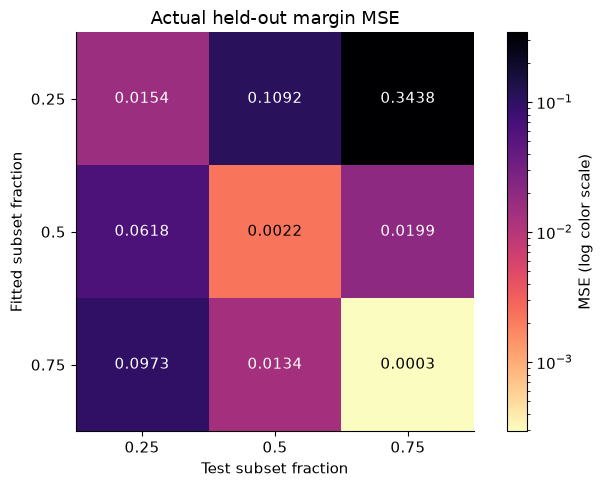

In [24]:
cross_mse = torch.tensor(
    [
        [
            float(
                (evaluated["cross_fraction"][target][source] - evaluated["test"][target]["margin"])
                .square()
                .mean()
            )
            for target in FRACTIONS
        ]
        for source in FRACTIONS
    ]
)
fig, ax = plt.subplots(figsize=(7, 5))
from matplotlib.colors import LogNorm

heat = ax.imshow(
    cross_mse,
    cmap="magma_r",
    norm=LogNorm(vmin=float(cross_mse.min()), vmax=float(cross_mse.max())),
)
for row in range(3):
    for col in range(3):
        ax.text(
            col,
            row,
            f"{cross_mse[row,col]:.4f}",
            ha="center",
            va="center",
            color="white" if cross_mse[row, col] > 0.01 else "black",
        )
ax.set(
    xticks=range(3),
    xticklabels=FRACTIONS,
    yticks=range(3),
    yticklabels=FRACTIONS,
    xlabel="Test subset fraction",
    ylabel="Fitted subset fraction",
    title="Actual held-out margin MSE",
)
fig.colorbar(heat, ax=ax, label="MSE (log color scale)")
show_figure(fig, "datamodel_cross_fraction")


## 9️⃣ Read coefficients as images, then confront them with retraining

The following gallery always uses the first two source-ordered queries of each
class. The datamodel fraction is 0.5. Compare its two largest and two smallest
coefficients with the two closest signed pixel neighbors. The score is relative
to the query's **correct-class margin**, not a universal value of the image.

Coefficients and pixel similarity can highlight different aspects of the same
task. A visually familiar image can be redundant; an opposing example can be
important because it constrains the decision boundary. The gallery suggests
hypotheses. The deletion experiment below tests them.


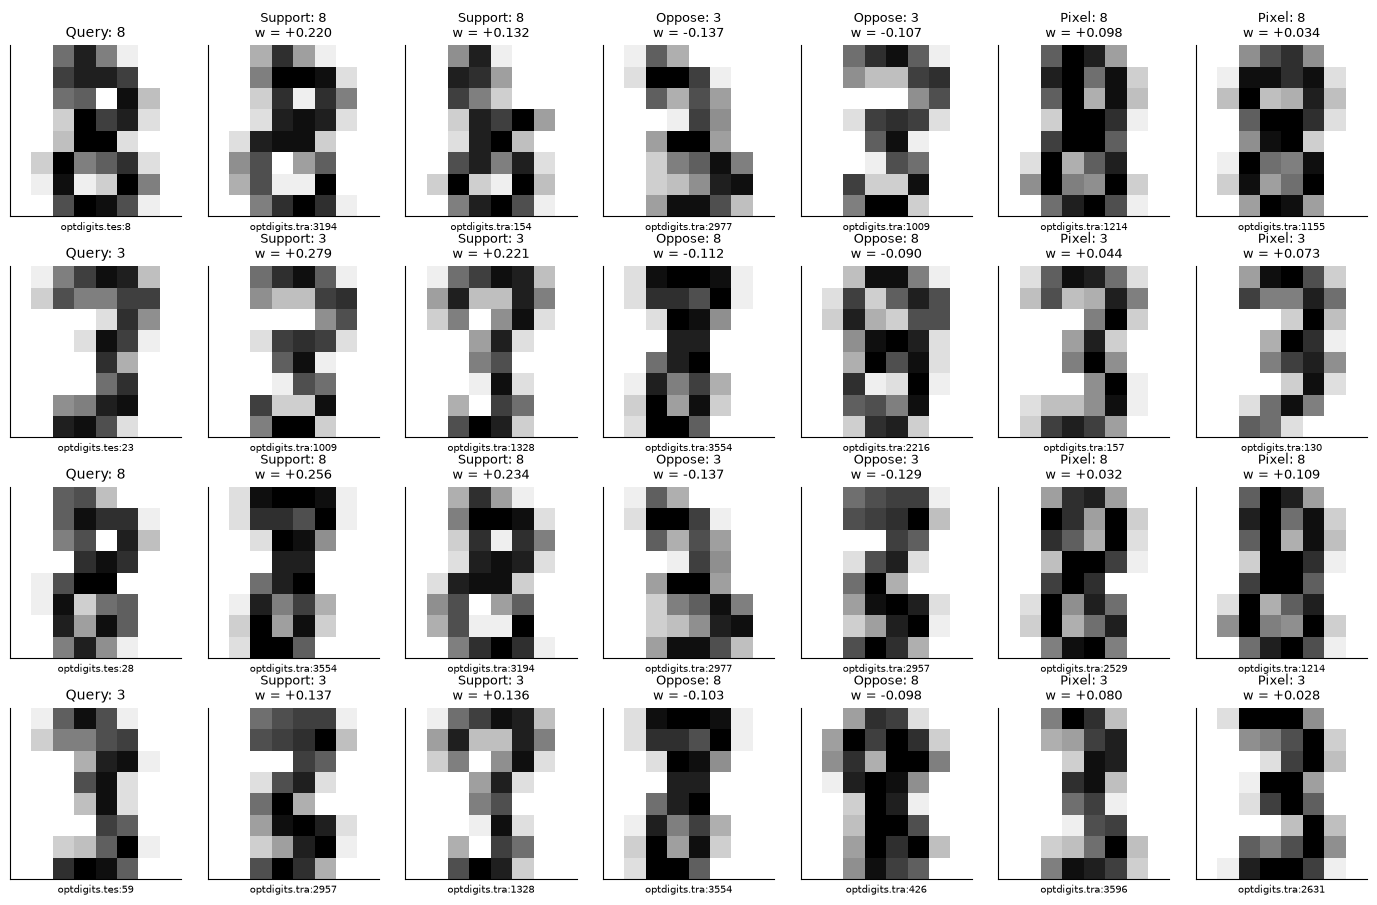

In [25]:
gallery = (
    torch.cat([torch.nonzero(query["y"] == label).flatten()[:2] for label in (0, 1)]).sort().values
)
weights = prepared["responses"][0.5]["lasso"]["selected_weights"]
fig, axes = plt.subplots(4, 7, figsize=(14, 9))
for row, q in enumerate(gallery.tolist()):
    w = weights[:, q]
    high = torch.argsort(w, descending=True, stable=True)[:2]
    low = torch.argsort(w, stable=True)[:2]
    close = torch.argsort(
        prepared["deletions"]["pixel_scores"][:, q], descending=True, stable=True
    )[:2]
    axes[row, 0].imshow(query["images"][q], cmap="gray_r", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Query: {query['digit'][q].item()}", fontsize=10)
    axes[row, 0].set_xlabel(query["ids"][q], fontsize=7)
    for col, (index, role) in enumerate(
        zip([*high, *low, *close], ["Support", "Support", "Oppose", "Oppose", "Pixel", "Pixel"]),
        start=1,
    ):
        axes[row, col].imshow(train["images"][index], cmap="gray_r", vmin=0, vmax=1)
        axes[row, col].set_title(
            f"{role}: {train['digit'][index].item()}\nw = {w[index]:+.3f}", fontsize=9
        )
        axes[row, col].set_xlabel(train["ids"][index], fontsize=7)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
show_figure(fig, "datamodel_coefficient_gallery")


### Similarity between target-specific datamodels

Use your centered-weight cosine function to compare the queries' directions in
training-image space. For readability, the figure orders queries by their source
label; that display order changes no fit. The control independently shuffles
the training-image coordinates in each target's weight vector, preserving its
values while destroying correspondence between image identities.

This is an exploratory representation, not evidence of duplicate images or
train/test leakage. Those claims would require inspecting the images and
checking provenance, as we did for exact pixel duplicates at the start.


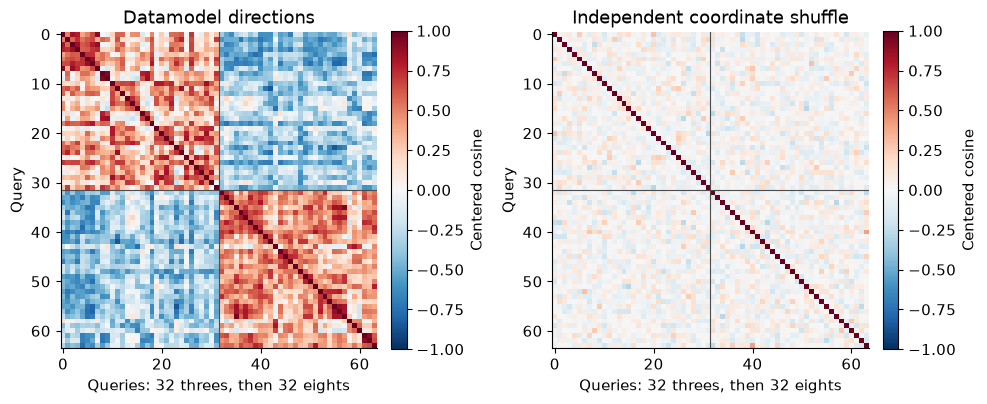

In [26]:
ordered = torch.argsort(query["y"], stable=True)
weights = prepared["responses"][0.5]["lasso"]["selected_weights"]
shuffled_weights = weights.clone()
generator = torch.Generator().manual_seed(161771)
for q in range(weights.shape[1]):
    shuffled_weights[:, q] = weights[torch.randperm(len(weights), generator=generator), q]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, current, title in zip(
    axes, [weights, shuffled_weights], ["Datamodel directions", "Independent coordinate shuffle"]
):
    similarity = centered_weight_similarity(current)[ordered][:, ordered]
    heat = ax.imshow(similarity, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.axvline(31.5, color="0.3", linewidth=0.8)
    ax.axhline(31.5, color="0.3", linewidth=0.8)
    ax.set(title=title, xlabel="Queries: 32 threes, then 32 eights", ylabel="Query")
    fig.colorbar(heat, ax=ax, fraction=0.046, pad=0.04, label="Centered cosine")
show_figure(fig, "datamodel_similarity")


### Did removing supportive images actually hurt the margin?

For each method and budget, the solid line is the mean observed margin change
across the 24 fixed queries. The dashed line is the datamodel prediction. The
gray band spans the sixteen matched-random replicate means; it is not a
confidence interval. The pixel baseline's predictions use the $\alpha=0.5$
datamodel for the images selected by pixel similarity.

All curves begin at zero for removing nothing. Negative means the correct-class
margin became smaller. The original full-pool classifier gets all 64 queries
right, so a later negative margin is an actual correct-to-incorrect transition.


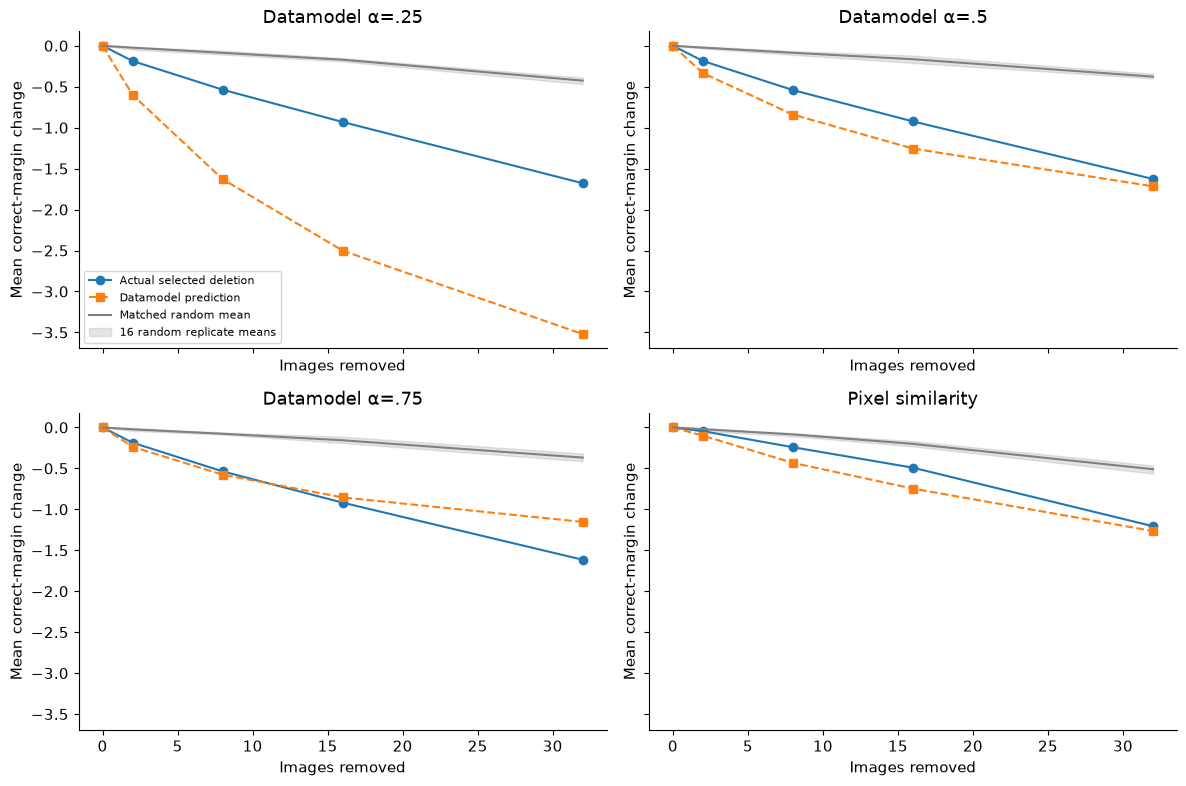

In [27]:
deletions = prepared["deletions"]
counterfactual = evaluated["counterfactual"]
method_labels = ["Datamodel α=.25", "Datamodel α=.5", "Datamodel α=.75", "Pixel similarity"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for method_index, (ax, label) in enumerate(zip(axes.flat, method_labels)):
    actual, prediction, low, high, average = [0.0], [0.0], [0.0], [0.0], [0.0]
    for budget in BUDGETS:
        scope = (deletions["method"] == method_index) & (deletions["budget"] == budget)
        chosen = scope & (deletions["replicate"] == -1)
        actual.append(float(counterfactual["actual_change"][chosen].mean()))
        prediction.append(
            float(
                counterfactual["predicted_change"][
                    chosen, method_index if method_index < 3 else 1
                ].mean()
            )
        )
        controls = torch.stack(
            [
                counterfactual["actual_change"][scope & (deletions["replicate"] == rep)].mean()
                for rep in range(16)
            ]
        )
        low.append(float(controls.min()))
        high.append(float(controls.max()))
        average.append(float(controls.mean()))
    budgets = [0, *BUDGETS]
    ax.plot(budgets, actual, "o-", label="Actual selected deletion")
    ax.plot(budgets, prediction, "s--", label="Datamodel prediction")
    ax.plot(budgets, average, color="0.5", label="Matched random mean")
    ax.fill_between(budgets, low, high, color="0.5", alpha=0.2, label="16 random replicate means")
    ax.set(title=label, xlabel="Images removed", ylabel="Mean correct-margin change")
axes[0, 0].legend(fontsize=8)
show_figure(fig, "datamodel_deletion_curves")


The rankings find consequential images, but calibration depends strongly on the
fitted fraction. At budget 32 the $\alpha=0.25$ datamodel predicts a mean change
of about −3.52; actual retraining gives −1.68. For $\alpha=0.75$, the prediction
is −1.15 and the observed change is −1.62. Neither sign of error should be hidden.

At the same budget, the three datamodel rankings flip 4, 3 and 3 of the 24 fixed
queries; pixel similarity flips 3. A flipped query supplies a tested upper bound
on its minimum deletion support. We did not search all subsets, so this is not
an exact minimum, and it is not a theorem about unseen queries or models.

The next plot keeps all 24 query outcomes visible at the largest prescribed
budget. Some averaged effects conceal a much more fragile individual prediction.
The shaded flip-count control spans all four methods and sixteen random
replicates: no random cohort flips a query at budgets 2, 8 or 16, while
the budget-32 cohorts flip between zero and one of the 24 queries.


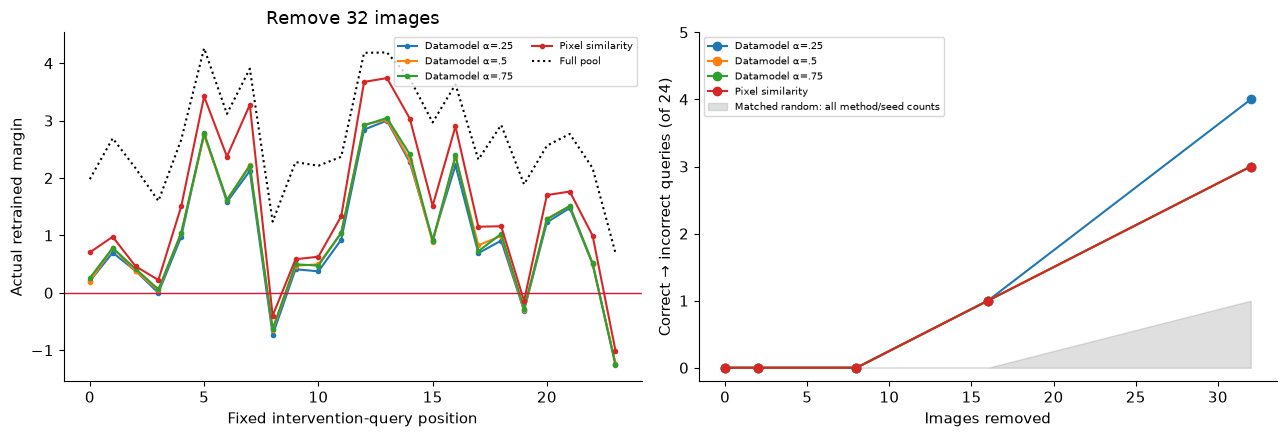

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for method_index, label in enumerate(method_labels):
    chosen = (
        (deletions["method"] == method_index)
        & (deletions["budget"] == 32)
        & (deletions["replicate"] == -1)
    )
    targets = deletions["target"][chosen]
    axes[0].plot(
        range(len(targets)),
        counterfactual["target_margin"][chosen],
        "o-",
        markersize=3,
        label=label,
    )
    flips = []
    for budget in BUDGETS:
        selected = (
            (deletions["method"] == method_index)
            & (deletions["budget"] == budget)
            & (deletions["replicate"] == -1)
        )
        flips.append(int((counterfactual["target_margin"][selected] < 0).sum()))
    axes[1].plot([0, *BUDGETS], [0, *flips], "o-", label=label)
axes[0].plot(
    range(24), evaluated["base_margin"][deletions["query_indices"]], "k:", label="Full pool"
)
axes[0].axhline(0, color="crimson", linewidth=1)
axes[0].set(
    xlabel="Fixed intervention-query position",
    ylabel="Actual retrained margin",
    title="Remove 32 images",
)
random_low, random_high = [0], [0]
for budget in BUDGETS:
    counts = []
    for method_index in range(4):
        for replicate in range(16):
            selected = (
                (deletions["method"] == method_index)
                & (deletions["budget"] == budget)
                & (deletions["replicate"] == replicate)
            )
            counts.append(int((counterfactual["target_margin"][selected] < 0).sum()))
    random_low.append(min(counts))
    random_high.append(max(counts))
axes[1].fill_between(
    [0, *BUDGETS],
    random_low,
    random_high,
    color="0.5",
    alpha=0.25,
    label="Matched random: all method/seed counts",
)
axes[1].legend(fontsize=7, loc="upper left")
axes[1].set(
    xlabel="Images removed", ylabel="Correct → incorrect queries (of 24)", yticks=range(0, 6)
)
axes[0].legend(fontsize=7, ncol=2)
show_figure(fig, "datamodel_individual_flips")


### Try It Yourself — choose a query and retrain its counterfactual

Change `QUERY_INDEX`, `SUBSET_FRACTION` or `REMOVAL_BUDGET`. The function fits a
full-pool base model, your selected deletion and sixteen class-matched random
deletions from scratch. It shows a query image, the removed images and the
observed margin changes. The vertical line is the datamodel's predicted change.

Try a query whose margin stayed positive in the reference study, then one close
to the decision boundary. Compare the two fractions that over- and underpredicted
the average effect. These explorations are additional experiments; they do not
replace any point in the frozen reference study.


In [29]:
def deletion_play(
    prepared: dict,
    train: dict,
    query: dict,
    methods,
    query_index: int = 0,
    fraction: float = 0.5,
    budget: int = 8,
) -> dict:
    """An editable intervention: base, selected deletion and sixteen random refits."""
    if not 0 <= query_index < len(query["y"]) or fraction not in FRACTIONS:
        raise ValueError("Choose an available query and fitted subsampling fraction.")
    weights = prepared["responses"][fraction]["lasso"]["selected_weights"][:, query_index]
    selected = methods.select_supportive(weights, budget)
    controls = methods.matched_random_removals(train["y"], selected, 16, 163001)
    removals = torch.cat([selected[None], controls])
    masks = torch.ones(18, len(train["y"]), dtype=torch.bool)
    for i, removed in enumerate(removals, start=1):
        masks[i, removed] = False
    fit = refit_masks(train, masks)
    margin = model_margins(fit, query, methods)[:, query_index]
    prediction = -(~masks).double() @ weights
    return dict(
        query_index=query_index,
        fraction=fraction,
        budget=budget,
        removals=removals,
        masks=masks,
        fit=fit,
        margin=margin,
        actual_change=margin - margin[0],
        predicted_change=prediction,
    )


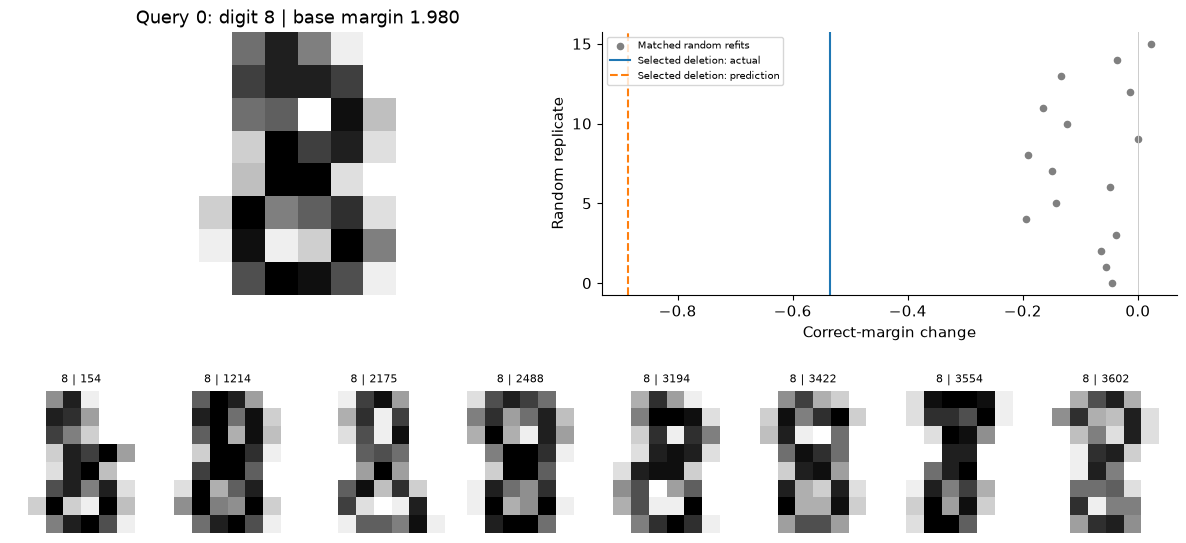

In [30]:
QUERY_INDEX = 0
SUBSET_FRACTION = 0.5
REMOVAL_BUDGET = 8

play = deletion_play(prepared, train, query, methods, QUERY_INDEX, SUBSET_FRACTION, REMOVAL_BUDGET)
torch.save(play, NATIVE / "play.pt")
fig = plt.figure(figsize=(12, 6.5))
grid = fig.add_gridspec(2, 2, height_ratios=[1, 1.25])
ax_query = fig.add_subplot(grid[0, 0])
ax_query.imshow(query["images"][QUERY_INDEX], cmap="gray_r", vmin=0, vmax=1)
ax_query.set_title(
    f"Query {QUERY_INDEX}: digit {query['digit'][QUERY_INDEX].item()} | base margin {play['margin'][0]:.3f}"
)
ax_query.axis("off")
ax_changes = fig.add_subplot(grid[0, 1])
ax_changes.scatter(
    play["actual_change"][2:], np.arange(16), color="0.5", s=20, label="Matched random refits"
)
ax_changes.axvline(float(play["actual_change"][1]), label="Selected deletion: actual", color="C0")
ax_changes.axvline(
    float(play["predicted_change"][1]),
    label="Selected deletion: prediction",
    color="C1",
    linestyle="--",
)
ax_changes.axvline(0, color="0.8", linewidth=0.7)
ax_changes.set(xlabel="Correct-margin change", ylabel="Random replicate", yticks=[0, 5, 10, 15])
ax_changes.legend(fontsize=7)
removed = play["removals"][0]
columns = min(8, max(1, len(removed)))
rows = math.ceil(max(1, len(removed)) / columns)
image_grid = grid[1, :].subgridspec(rows, columns)
for position in range(rows * columns):
    ax = fig.add_subplot(image_grid[position // columns, position % columns])
    if position < len(removed):
        i = removed[position]
        ax.imshow(train["images"][i], cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(f"{train['digit'][i].item()} | {train['ids'][i].split(':')[-1]}", fontsize=8)
    ax.axis("off")
show_figure(fig, "datamodel_real_play")


## Interpreting the result

You have predicted a real classifier's output using only the identities of its
training images. Accurate held-out-subset prediction survives a per-query check,
and permuting the mask/response association destroys it. The training outputs,
not a report or precomputed explanation, supplied the supervision.

You also found an important boundary. Predictions learned at one subset size do
not automatically carry over to another. The same coefficient ranking can
identify damaging deletions while its predicted effect size is wrong. Actual
retraining, class-matched controls and the offset derivation let you distinguish
these claims.

## Limitations and further investigations

- The base learner is a small deterministic convex classifier. The paper studies
  stochastic deep networks and expected outputs across training randomness.
  This lesson does not reproduce that noise floor, architecture or data scale.
- The 64 query images are held out from classifier fitting. They are deliberately
  present as datamodel targets; the 256 test **subsets** per fraction are the
  unseen inputs used for our central predictive evaluation.
- Most selected coefficient vectors are dense. Lasso and least squares are
  close here, and many validation choices hit the weakest tested penalty.
- Deletion rankings and their controls test particular subsets. An observed flip
  bounds the minimum support from above; it does not find a globally minimal set.
- Coefficient similarity is exploratory. It does not establish duplicate data,
  semantic equivalence, universal example value or an exact Shapley allocation.

For anomaly hunting, start with the worst per-query held-out prediction. Inspect
its image and the masks with large errors. Then compare two deletion sets with
similar predicted changes and different actual outcomes. Is class composition
enough to explain the difference? What additional interaction would a linear
datamodel need to represent it?

## Reading

- [Ilyas et al. (2022), Datamodels: Understanding Predictions with Data and Data with Predictions](https://proceedings.mlr.press/v162/ilyas22a.html).
  Sections 1–3 give the framework, fixed-size sampling and sparse regression;
  section 4 tests data counterfactuals. The linked PDF retains an earlier title.
- [The authors' Datamodels implementation](https://github.com/MadryLab/datamodels).
  Its separation between subset training and regression is useful when scaling
  beyond the CPU-sized experiment here.
- [16.9 Influence Functions and TracIn](../part9_influence_and_tracin/README.md).
  Compare the estimands: local upweight derivatives, checkpoint gradient
  agreement, and a learned predictor of complete subset retraining outcomes.


In [31]:
# Independent numerical checks and reproducibility metadata support the figures above.
from chapter16_shapley_attribution_baselines.exercises.part10_datamodels.run_native import (
    reference_checks,
)

references = reference_checks(data, prepared, evaluated)
gradient_values = [
    fit["gradient_norm"].max()
    for values in prepared["subset_fits"].values()
    for fit in values.values()
]
gradient_values += [value["fit"]["gradient_norm"].max() for value in evaluated["test"].values()]
gradient_values += [
    evaluated["base_fit"]["gradient_norm"].max(),
    counterfactual["fit"]["gradient_norm"].max(),
]
summary = {
    "native_directory": str(NATIVE),
    "classifier_refits": 10753,
    "separate_refits": 6,
    "independent_scipy_optima": 10,
    "independent_lasso_fits": 12,
    "play_refits": 18,
    "train_images": 128,
    "query_images": 64,
    "heldout_subsets_per_fraction": 256,
    "selection_used_test_responses": False,
    "max_classifier_gradient": float(torch.stack(gradient_values).max()),
    "base_query_correct": int((evaluated["base_margin"] > 0).sum()),
}
(OUTPUT / "native_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
(OUTPUT / "reference_checks.json").write_text(json.dumps(references, indent=2) + "\n")
print("Independent classifier and Lasso checks passed. All native fits and figures are saved.")


Independent classifier and Lasso checks passed. All native fits and figures are saved.
